# A small quantum signal-processing circuit

This bounded circuit implements the degree-two Chebyshev response $T_2(H)=2H^2-I$ for $H=0.6Z+0.4X$, normalized by coefficient sum one. The phase sequence is $(-\pi/2,\pi/2,0)$. It is an exact polynomial demonstration in the ideal angle model, not a full evolution or an efficient accepted-output preparation: the accepted block is $0.04I$.

In [1]:
from pathlib import Path
import sys
root = Path.cwd()
if (root / "src").exists(): sys.path.insert(0, str(root / "src"))
from openquantum.simulation.qsp import build_real_qsp_filter
from openquantum.hamiltonian_simulation import decompose
from qiskit.quantum_info import Operator
import numpy as np
terms = ((0.6, "Z"), (0.4, "X"))
circuit = build_real_qsp_filter(terms, phases=(-np.pi/2, np.pi/2, 0.))
Z = np.diag([1., -1.]); X = np.array([[0., 1.], [1., 0.]])
H = 0.6 * Z + 0.4 * X
expected = 2 * H @ H - np.eye(2)
actual = Operator(circuit).data[:2, :2]
np.testing.assert_allclose(actual, expected, atol=1e-12, rtol=0)
print("Actual accepted block:", np.real_if_close(actual))
print("Acceptance for every system input:", float(np.linalg.norm(actual[:, 0])**2))

Actual accepted block: [[ 4.00000000e-02 -7.85046229e-17]
 [ 7.85046229e-17  4.00000000e-02]]
Acceptance for every system input: 0.0015999999999999955


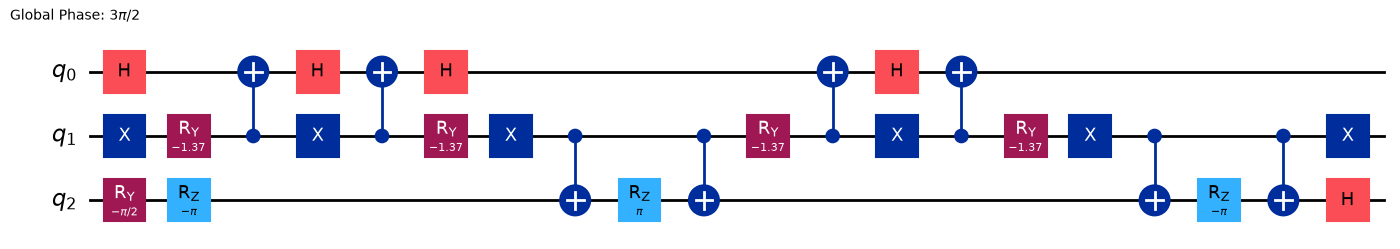

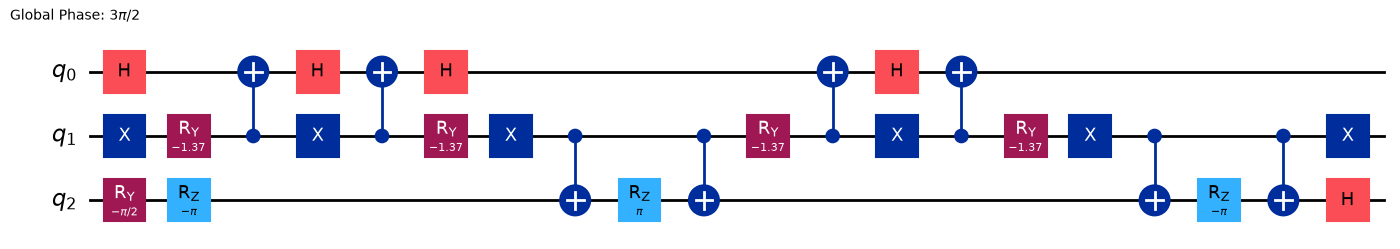

In [2]:
from IPython.display import display
compiled = decompose(circuit)
figure = compiled.draw(output="mpl", fold=28, style={"backgroundcolor": "#FFFFFF"})
display(figure)